# Detecting emotions with ML algorithms 

**Course:** 5ARE0, Academic Year 2026/2027
**Assignment 2, Group 2**

| Name | Student number |
|---|---|
| Gabriele Salvo | 2140004 |
| Valērijs Gončarovs | 2565161 |
| Herman Chang | 2406748 |

**Deadline:** 25 October 2026, 23:59

---

## Objective

Build a tool that classifies a stretch of bicycle lane as **smooth** or **bumpy** from the
inertial sensors of a smartphone (accelerometer, gyroscope, gravity), recorded with the
*Sensor Logger* app while cycling.

The notebook implements the pipeline of Section 3 of the assignment brief and follows the
CRISP-DM phases:

| CRISP-DM phase | Notebook section |
|---|---|
| Business / Objective Understanding | 1 |
| Data Understanding | 2, 3 and 4 |
| Data Preparation | 5, 6 and 7 |
| Modelling | 8 and 9 |
| Evaluation | 8.5 to 8.11, 9.3 and 10 |
| Deployment | 11 |
| Conclusions and recommendations | 12 |

**How to run.** Put the raw Sensor Logger exports in `data/raw/` (naming convention in
Section 3) and the external dataset in `DeploymentData/`, select the `Python (group2)` kernel
and run *Kernel > Restart & Run All*. The notebook imports no local `.py` files. A full run
takes roughly 15 minutes on a laptop; the nested cross-validation of Section 8.10 is the
slowest step.

In [57]:
# Automatically re-import files when updated
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [58]:
import os
import joblib
import numpy as np
import pandas as pd
import dlib
import cv2
import matplotlib.pyplot as plt
import torch
import imagehash

from facenet_pytorch import MTCNN
from tqdm import tqdm
from PIL import Image
from pathlib import Path

from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

DATASET_PATH = "datasets/fer2013.csv"
SANITIZED_DATASET_PATH = "datasets/fer2013_sanitized.csv"
PREDICTOR_PATH = "landmark_detectors/shape_predictor_68_face_landmarks.dat"

MODEL_PATH = "models"
N_LANDMARKS = 68
CONFIDENCE_THRESHOLD = 0.7
UPSCALE = 192

# Set up GPU

In [59]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


In [60]:
detector = MTCNN(
    keep_all=True,
    device=device,
    thresholds=[0.6, 0.7, 0.75],
    min_face_size=20,
)

In [61]:
def load_fer2013_dataset(csv_path, sanitized_csv_path):

    path = Path(sanitized_csv_path)

    if not path.exists():
        df = pd.read_csv(csv_path)
        df = filter_bad_inputs(df)
        df = balance_classes(df)
        df = remove_duplicates(df)
        df.to_csv(sanitized_csv_path)
    else:
        df = pd.read_csv(csv_path)

    # Filter for the training split
    train_df = df[df['Usage'] == 'Training']
    val_df = df[df['Usage'] == 'PublicTest']
    test_df = df[df['Usage'] == 'PrivateTest']

    X_train, y_train = build_features(train_df)

    X_val, y_val = build_features(val_df)

    X_test, y_test = build_features(test_df)

    return X_train, y_train, X_val, y_val, X_test, y_test

In [62]:
def build_features(df):
    X = []
    y = df["emotion"].to_numpy(dtype=np.int64)

    predictor = dlib.shape_predictor(PREDICTOR_PATH)

    for pixel_sequence in df["pixels"]:
        image = np.array(pixel_sequence.split(), dtype=np.uint8).reshape(48, 48)
        image = cv2.resize(image, (UPSCALE, UPSCALE), interpolation=cv2.INTER_CUBIC)

        features = extract_landmarks(image, predictor)
        X.append(features)

    return X, y

In [63]:
def balance_classes(df, max_samples_per_class=4000):
    print(df['emotion'].value_counts())
    
    balanced_chunks = []
    
    for emotion_id, group in df.groupby('emotion'):
        if len(group) > max_samples_per_class:
            sampled_group = group.sample(n=max_samples_per_class, random_state=42)
            balanced_chunks.append(sampled_group)
        else:
            balanced_chunks.append(group)
            
    df = pd.concat(balanced_chunks).sample(frac=1, random_state=42).reset_index(drop=True)
    
    return df


In [64]:
def filter_bad_inputs(df):
    keep = []
    for pixel_sequence in df["pixels"]:
        image = np.array(pixel_sequence.split(), dtype=np.uint8).reshape(48, 48)
        image = cv2.resize(image, (UPSCALE, UPSCALE), interpolation=cv2.INTER_CUBIC)
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)

        _, probs = detector.detect(image)
        keep.append(probs is not None and np.nanmax(np.asarray(probs, dtype=float)) >= CONFIDENCE_THRESHOLD)

    return df[np.array(keep, dtype=bool)].reset_index(drop=True)

In [65]:
def remove_duplicates(df):
    seen = set()                      
    keep = []

    for pixel_sequence in df["pixels"]:
        image = np.array(pixel_sequence.split(), dtype=np.uint8).reshape(48, 48)
        img_hash = str(imagehash.dhash(Image.fromarray(image)))

        keep.append(img_hash not in seen)     
        seen.add(img_hash)

    keep = np.array(keep, dtype=bool)
    return df[keep].reset_index(drop=True)

In [66]:
def extract_landmarks(image, predictor):
    """
    Extract 68 facial landmarks as raw (x, y) coordinates.

    Input:
        image: 48x48 grayscale image, values in [0, 255]
        predictor: dlib.shape_predictor object

    Output:
        Feature vector of shape (136,), x and y in [0, 1] relative to image size.
        Returns zeros if extraction fails.
    """
    try:
        image = np.asarray(image, dtype=np.uint8)

        # FER2013 images are already face crops, so skip the face detector and
        # pass the whole image to the predictor as the face rectangle.
        rect = dlib.rectangle(0, 0, UPSCALE - 1, UPSCALE - 1)
        shape = predictor(image, rect)

        features = np.array(
            [[p.x / UPSCALE, p.y / UPSCALE] for p in shape.parts()],
            dtype=np.float32
        ).flatten()
        return features

    except Exception:
        return np.zeros(N_LANDMARKS * 2, dtype=np.float32)

In [67]:
X_train, y_train, X_val, y_val, X_test, y_test = (
    load_fer2013_dataset(DATASET_PATH, SANITIZED_DATASET_PATH)
)

C:\Users\Legion Pro\AppData\Local\Temp\ipykernel_12992\3256190012.py:9: RuntimeWarning: All-NaN slice encountered
  keep.append(probs is not None and np.nanmax(np.asarray(probs, dtype=float)) >= CONFIDENCE_THRESHOLD)


emotion
3    7787
6    5551
4    4679
0    4187
2    4108
5    3462
1     419
Name: count, dtype: int64


In [68]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1,
    bootstrap=True
)

param_grid = {
    "n_estimators":     [300, 500, 800],
    "max_depth":        [None, 20, 30, 40],
    "min_samples_leaf": [1, 2, 4, 8],
    "min_samples_split":[2, 5, 10],
    "max_features":     ["sqrt", "log2", 0.2, 0.35],
    "class_weight":     [None, "balanced", "balanced_subsample"],
    "max_samples":      [None, 0.7, 0.9],   # only used with bootstrap=True (the default)
}


grid_search = RandomizedSearchCV(
    rf_model,
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_val, y_val)

print("Best parameters:", grid_search.best_params_)
print("Best CV macro F1:", round(grid_search.best_score_, 4))

c:\Users\Legion Pro\miniconda3\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best parameters: {'n_estimators': 800, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_samples': 0.7, 'max_features': 0.35, 'max_depth': None, 'class_weight': 'balanced_subsample'}
Best CV macro F1: nan


In [69]:
rf_model = RandomForestClassifier(
    n_estimators=grid_search.best_params_["n_estimators"],
    max_depth=grid_search.best_params_["max_depth"],
    min_samples_leaf=grid_search.best_params_["min_samples_leaf"],
    min_samples_split=grid_search.best_params_["min_samples_split"],
    max_features=grid_search.best_params_["max_features"],
    class_weight=grid_search.best_params_["class_weight"],
    max_samples=grid_search.best_params_["max_samples"],
    random_state=42,
    n_jobs=-1,
    bootstrap=True
)
    

In [70]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

param_grid = {
    "lr__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    "lr__solver": ["lbfgs", "saga"],
    "lr__class_weight": [None, "balanced"],
    "lr__tol": [1e-4, 1e-3],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_val, y_val)

print("Best parameters:", grid_search.best_params_)
print("Best CV macro F1:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters: {'lr__C': 1.0, 'lr__class_weight': None, 'lr__solver': 'saga', 'lr__tol': 0.001}
Best CV macro F1: 0.3909


In [71]:
lr_model = LogisticRegression(
    C=grid_search.best_params_["lr__C"],
    solver=grid_search.best_params_["lr__solver"],
    class_weight=grid_search.best_params_["lr__class_weight"],
    tol=grid_search.best_params_["lr__tol"],
    max_iter=5000,
    random_state=42
)

In [72]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        probability=False,
        random_state=42
    ))
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1],
    "svm__class_weight": [None, "balanced"],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

svm_search.fit(X_val, y_val)

print("Best parameters:", svm_search.best_params_)
print("Best CV macro F1:", round(svm_search.best_score_, 4))

Fitting 5 folds for each of 32 candidates, totalling 160 fits


c:\Users\Legion Pro\miniconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best parameters: {'svm__C': 100, 'svm__class_weight': None, 'svm__gamma': 0.001}
Best CV macro F1: 0.3709


In [73]:
svm_model = SVC(
    C=svm_search.best_params_["svm__C"],
    gamma=svm_search.best_params_["svm__gamma"],
    class_weight=svm_search.best_params_["svm__class_weight"],
    kernel="rbf",
    probability=False,
    random_state=42
)

In [74]:
os.makedirs(MODEL_PATH, exist_ok=True)

# Save Random Forest model
model_file = os.path.join(MODEL_PATH, "rf_for_fer2013.pkl")
joblib.dump(rf_model, model_file)

# Save Logistic Regression model
model_file = os.path.join(MODEL_PATH, "lr_for_fer2013.pkl")
joblib.dump(lr_model, model_file)

# Save SVM model
model_file = os.path.join(MODEL_PATH, "svm_for_fer2013.pkl")
joblib.dump(svm_model, model_file)

['models\\svm_for_fer2013.pkl']

In [75]:
rf_model.fit(X_train, y_train)

# Validation evaluation
rf_val_pred = rf_model.predict(X_val)

print("Random Forest Validation accuracy:", accuracy_score(y_val, rf_val_pred))
print("Random Forest Validation macro F1:", f1_score(y_val, rf_val_pred, average="macro"))

lr_model.fit(X_train, y_train)

# Validation evaluation
lr_val_pred = lr_model.predict(X_val)

print("Logistic Regression Validation accuracy:", accuracy_score(y_val, lr_val_pred))
print("Logistic Regression Validation macro F1:", f1_score(y_val, lr_val_pred, average="macro"))

svm_model.fit(X_train, y_train)

# Validation evaluation
svm_val_pred = svm_model.predict(X_val)

print("SVM Validation accuracy:", accuracy_score(y_val, svm_val_pred))
print("SVM Validation macro F1:", f1_score(y_val, svm_val_pred, average="macro"))

Random Forest Validation accuracy: 0.424502712477396
Random Forest Validation macro F1: 0.38061442297217496
Logistic Regression Validation accuracy: 0.44168173598553345
Logistic Regression Validation macro F1: 0.3701351205319813


c:\Users\Legion Pro\miniconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Validation accuracy: 0.4163652802893309
SVM Validation macro F1: 0.34945945300486564


In [76]:
# Final test evaluation
rf_test_pred = rf_model.predict(X_test)

print("Random Forest Test accuracy:", accuracy_score(y_test, rf_test_pred))
print("Random Forest Test macro F1:", f1_score(y_test, rf_test_pred, average="macro"))

print("Classification Report — Random Forest on FER2013")
print(classification_report(
    y_test,
    rf_test_pred,
    labels=list(range(7)),
    target_names=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
    zero_division=0
))

# Final test evaluation
lr_test_pred = lr_model.predict(X_test)

print("Logistic Regression Test accuracy:", accuracy_score(y_test, lr_test_pred))
print("Logistic Regression Test macro F1:", f1_score(y_test, lr_test_pred, average="macro"))

print("Classification Report — Logistic Regression on FER2013")
print(classification_report(
    y_test,
    lr_test_pred,
    labels=list(range(7)),
    target_names=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
    zero_division=0
))

# Final test evaluation
svm_test_pred = svm_model.predict(X_test)

print("SVM Test accuracy:", accuracy_score(y_test, svm_test_pred))
print("SVM Test macro F1:", f1_score(y_test, svm_test_pred, average="macro"))

print("Classification Report — SVM on FER2013")
print(classification_report(
    y_test,
    svm_test_pred,
    labels=list(range(7)),
    target_names=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
    zero_division=0
))

Random Forest Test accuracy: 0.4407158836689038
Random Forest Test macro F1: 0.40132496551907526
Classification Report — Random Forest on FER2013
              precision    recall  f1-score   support

       Angry       0.38      0.32      0.35       368
     Disgust       0.80      0.11      0.20        36
        Fear       0.36      0.20      0.26       376
       Happy       0.56      0.70      0.62       373
         Sad       0.35      0.34      0.34       395
    Surprise       0.58      0.56      0.57       289
     Neutral       0.40      0.58      0.47       398

    accuracy                           0.44      2235
   macro avg       0.49      0.40      0.40      2235
weighted avg       0.44      0.44      0.43      2235

Logistic Regression Test accuracy: 0.4425055928411633
Logistic Regression Test macro F1: 0.3713667292736259
Classification Report — Logistic Regression on FER2013
              precision    recall  f1-score   support

       Angry       0.39      0.43      

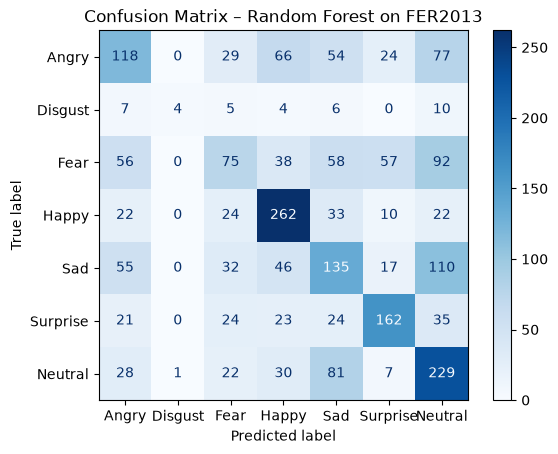

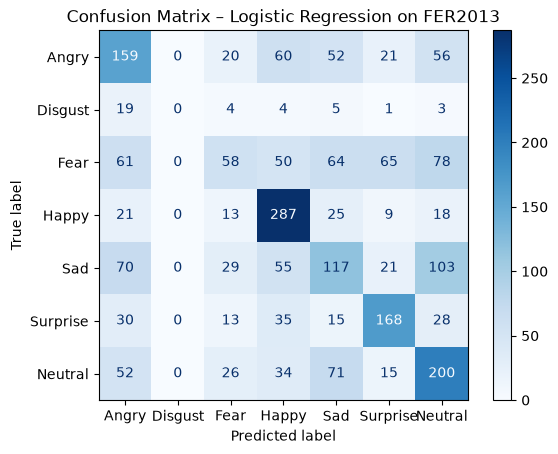

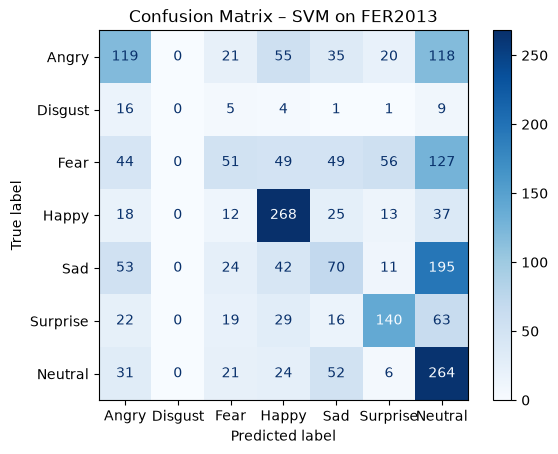

In [77]:
rf_score = confusion_matrix(y_test, rf_test_pred)
lr_score = confusion_matrix(y_test, lr_test_pred)
svm_score = confusion_matrix(y_test, svm_test_pred)

# Building a confusion matrix based on evaluation results
cm = ConfusionMatrixDisplay(
    rf_score, 
    display_labels=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],)
cm.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Random Forest on FER2013")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()


cm = ConfusionMatrixDisplay(
    lr_score,
    display_labels=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
)
cm.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Logistic Regression on FER2013")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()


cm = ConfusionMatrixDisplay(
    svm_score,
    display_labels=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
)
cm.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – SVM on FER2013")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

In [ ]:
orig_fer = pd.read_csv(DATASET_PATH)
sanit_fer = pd.read_csv(SANITIZED_DATASET_PATH)
print(f"Original fer shape: {orig_fer.shape}")
print(f"Sanitized fer shape: {sanit_fer.shape}")

TypeError: can only concatenate str (not "tuple") to str